# ERA5 — SpatialPCA Evaluation

Evaluates the [SpatialPCA](https://github.com/shangll123/SpatialPCA) baseline on ERA5 data.
SpatialPCA is an R package; embeddings are computed by calling out to
`ERA5/spatialpca/execute_spatialpca.R` (run in the separate `spatialpca` conda env) via
subprocess, the same pattern the existing UMAP baseline uses. `CreateSpatialPCAObject()`'s
built-in Seurat/SCTransform normalization step is bypassed — it's designed for non-negative
RNA-seq count data, and ERA5's z-scored features are already normalized and can be negative — by
constructing the `SpatialPCA` S4 object directly with `normalized_expr` set from ERA5's own
normalized features. The downstream computation (`SpatialPCA_buildKernel` →
`SpatialPCA_EstimateLoading` → `SpatialPCA_SpatialPCs`) is pure linear algebra on that matrix and
the spatial coordinates, with no non-negativity requirement.

Three experiments (same setup as `ERA5/notebooks/phate_evaluation.ipynb`):

1. **Distance preservation** — how well SpatialPCA's low-dimensional embedding preserves pairwise
   distances from the original feature space, globally and locally.
2. **Patch stitching** — split the region into two adjacent patches A and B, embed each
   independently with SpatialPCA, match points along the shared border to their nearest neighbor
   in the adjacent patch, and report two normalized errors, **SE-region** and **SE-local**.
3. **Patch gluing** — split the region into two overlapping patches, match points near the shared
   border to their nearest neighbor in the other patch, and measure MSE between the two
   independently-computed embeddings at those matched points.


In [28]:
# ── Safe imports and runtime settings ─────────────────────────────────────────
# torch and faiss (k-NN/perplexity graph construction) loaded into one process with
# unconstrained thread pools can make macOS abort with a duplicate-OpenMP-runtime error (or
# segfault outright). Capping thread counts before those libraries import, plus the (unsafe
# but standard) escape hatch as a second line of defense, avoids it.
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('NUMEXPR_NUM_THREADS', '1')
os.environ.setdefault('NUMBA_NUM_THREADS', '1')

import random
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

project_root = Path.cwd().parent.parent
import sys
sys.path.append(str(project_root / 'ERA5' / 'scripts'))
sys.path.append(str(Path.cwd()))

from utilities_era5 import ERA5_Graph_Generator as Data_Generator
from plot_utils_era5 import rgb, rgb_scale

data_path = project_root / 'ERA5' / 'data'
SPATIALPCA_DIR = project_root / 'ERA5' / 'spatialpca'


## Configuration

In [29]:
VARS = ["w", "v", "z", "q", "r", "t", "d", "o3", "pv", "u", "vo"]

# lon_min, lat_min, lon_max, lat_max
BBOX_FULL = (-10, 30, 30, 70)

DATES = pd.date_range("2018-01-01", "2018-01-05").strftime("%Y-%m-%d").tolist()

K = 10
PERPLEXITY = 10
SAMPLING_METHOD = 'random'
FEATURE_MODE = 'channel_and_position'
SIGMA_METHOD = 'ones'

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

Generator = Data_Generator(data_path)

_call_counter = 0


def spatialpca_embed(X, coords, n_components=3):
    # Round-trips through R via subprocess, matching the existing UMAP baseline's pattern
    # (ERA5/umap/execute_umap.py, invoked with conda run -n <env>). Each call gets a unique
    # id so concurrent/repeated runs never collide on the same buffer files.
    global _call_counter
    _call_counter += 1
    call_id = f'spca_buffer_{_call_counter}'

    x_path = SPATIALPCA_DIR / f'{call_id}_X.csv'
    coords_path = SPATIALPCA_DIR / f'{call_id}_coords.csv'
    res_path = SPATIALPCA_DIR / f'res_{call_id}.csv'

    np.savetxt(x_path, X, delimiter=',')
    np.savetxt(coords_path, coords, delimiter=',')

    result = subprocess.run(
        ['conda', 'run', '-n', 'spatialpca', 'Rscript', 'execute_spatialpca.R', call_id, str(n_components)],
        cwd=SPATIALPCA_DIR, capture_output=True, text=True,
    )

    x_path.unlink(missing_ok=True)
    coords_path.unlink(missing_ok=True)

    if result.returncode != 0:
        raise RuntimeError(f'SpatialPCA failed for {call_id}:\n{result.stderr[-2000:]}')

    Y = np.loadtxt(res_path, delimiter=',', skiprows=1)
    res_path.unlink(missing_ok=True)
    return Y


def mean_std_str(values):
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.3f} \u00b1 {values.std(ddof=1):.3f}"


## 1. Distance Preservation

For each date, sample a graph over the full region, embed its node features with SpatialPCA, and
compare pairwise distances in the original feature space against pairwise distances in the
SpatialPCA embedding — globally (all pairs) and locally (the graph's own k/perplexity-based
`edge_index`, i.e. domain-neighbors, not an ad hoc k-NN).

`Stress-1` and `Stress-local` are:

$$\text{Stress-1} = \sqrt{\frac{\sum_{i<j}(d^y_{ij}-d^z_{ij})^2}{\sum_{i<j}(d^y_{ij})^2}}
\qquad
\text{Stress-local} = \sqrt{\frac{\sum_{(i,j)\in E}(d^y_{ij}-d^z_{ij})^2}{\sum_{(i,j)\in E}(d^y_{ij})^2}}$$

where $y$ is the original feature space, $z$ is the SpatialPCA embedding, and $E$ is the graph's
domain-neighbor edge set. `stress()` computes Stress-1 over all pairs; `edge_stress()` computes
Stress-local over just the edges in $E$.


In [30]:
def pairwise_distances(X):
    norms = np.sum(X**2, axis=1, keepdims=True)
    dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
    return np.sqrt(dist2)


def distance_preservation(H, L):
    DH, DL = pairwise_distances(H), pairwise_distances(L)
    i = np.triu_indices_from(DH, k=1)
    return np.corrcoef(DH[i], DL[i])[0, 1]


def stress(H, L):
    DH, DL = pairwise_distances(H), pairwise_distances(L)
    i = np.triu_indices_from(DH, k=1)
    dH, dL = DH[i], DL[i]
    return np.sqrt(np.sum((dH - dL) ** 2) / np.sum(dH ** 2))


def edge_distances(X, edge_indices):
    # edge_indices is [2, E]: row 0 = source nodes, row 1 = target nodes.
    diff = X[edge_indices[0]] - X[edge_indices[1]]
    return np.linalg.norm(diff, axis=1)


def edge_distance_preservation(H, L, edge_indices):
    return np.corrcoef(edge_distances(H, edge_indices), edge_distances(L, edge_indices))[0, 1]


def edge_stress(H, L, edge_indices):
    dH, dL = edge_distances(H, edge_indices), edge_distances(L, edge_indices)
    return np.sqrt(np.sum((dH - dL) ** 2) / np.sum(dH ** 2))


In [31]:
distance_records = []
for date in DATES:
    N = random.randint(1000, 5000)
    Generator.load_data(bbox=BBOX_FULL, vars=VARS, filename=f'{date}.nc')
    graph = Generator.sample_graph(
        N=N, k=K, perplexity=PERPLEXITY, sampling_method=SAMPLING_METHOD,
        gen_feature_mode=FEATURE_MODE, sigma_method=SIGMA_METHOD,
    )

    X = graph.normed_values.detach().cpu().numpy()
    coords = graph.normed_coords.detach().cpu().numpy()
    edge_indices = graph.edge_index.detach().cpu().numpy()

    print(f'{date}: running SpatialPCA on {X.shape[0]} points ...', end='\r')
    Y = spatialpca_embed(X, coords)

    distance_records.append({
        'date': date,
        'corr_global': distance_preservation(X, Y),
        'Stress-1': stress(X, Y),
        'corr_local': edge_distance_preservation(X, Y, edge_indices),
        'Stress-local': edge_stress(X, Y, edge_indices),
    })

print('Done.                                          ')
distance_preservation_df = pd.DataFrame(distance_records).set_index('date')
distance_preservation_df


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: divide by zero encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: overflow encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: invalid value encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: divide by zero encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: overflow encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: invalid value encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: divide by zero encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: overflow encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: invalid value encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: divide by zero encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: overflow encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: invalid value encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)


Done.                                          ..


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: divide by zero encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: overflow encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_52841/1960147597.py:3: RuntimeWarning: invalid value encountered in matmul
  dist2 = np.maximum(norms + norms.T - 2 * X @ X.T, 0.0)


,corr_global,Stress-1,corr_local,Stress-local
date,,,,
2018-01-01,0.233979,2.185161,0.375511,2.285114
2018-01-02,0.359907,0.695645,0.423500,0.988054
2018-01-03,0.488771,0.553438,0.462864,0.820820
2018-01-04,0.264047,1.521195,0.380850,1.749472
2018-01-05,0.358503,0.869802,0.388880,1.064221


In [32]:
# mean +- std across dates
distance_preservation_df.agg(mean_std_str).rename('SpatialPCA').to_frame()


,SpatialPCA
corr_global,0.341 ± 0.100
Stress-1,1.165 ± 0.680
corr_local,0.406 ± 0.037
Stress-local,1.382 ± 0.617


## 2. Patch Stitching

Split the full region into two adjacent, non-overlapping patches A and B (left/right by
longitude) and embed each independently with SpatialPCA. `A_B` is the 2°-wide border region
inside A closest to B, and `B_A` is the border region inside B closest to A. Each point in `A_B`
is matched to its nearest neighbor (in `normed_coords`, i.e. normalized ECEF space) in `B_A`, and
vice versa. For each matched pair `(a, b_N(a))`, two normalized stitching errors are reported:

- **SE-region**: `d(z_a, z_{b_N(a)})` normalized by the mean pairwise feature distance of *all*
  points inside `a`'s own border region.
- **SE-local**: the same numerator normalized instead by `d(z_a, z_{a_N(a)})`, the distance from
  `a` to its own nearest neighbor *within* its own border region — a per-point, local
  normalization rather than a regional average.

Both directions (A_B → B_A and B_A → A_B) are computed. The final SE-region and SE-local values
are reported as mean ± std across dates.


In [33]:
lon_min, lat_min, lon_max, lat_max = BBOX_FULL
lon_mid = (lon_min + lon_max) / 2

bbox_A = lon_min, lat_min, lon_mid, lat_max
bbox_B = lon_mid, lat_min, lon_max, lat_max

EDGE_MARGIN = 2  # degrees, border region width
N_POINTS_PATCH = 1000


def mean_dist(x):
    # SE-region normalizer: mean pairwise feature distance within a border region
    n = x.shape[0]
    dists = torch.cdist(x, x)
    return dists.triu(diagonal=1).sum() / (n * (n - 1) / 2)


def nearest_within(coords, emb):
    # SE-local normalizer: for each point, the feature distance to its own nearest
    # neighbor (by normed_coords) within the same border region
    tree = cKDTree(coords)
    _, idx = tree.query(coords, k=2)  # column 0 is the point itself
    nn_idx = idx[:, 1]
    return torch.norm(emb - emb[nn_idx], dim=1)


def patch_stitching_errors(coords_A, emb_A, coords_B, emb_B):
    A = torch.from_numpy(emb_A)
    B = torch.from_numpy(emb_B)

    records = []
    for src_coords, src_emb, dst_coords, dst_emb in [(coords_A, A, coords_B, B), (coords_B, B, coords_A, A)]:
        tree_dst = cKDTree(dst_coords)
        _, idx_matched = tree_dst.query(src_coords)
        raw_dist = torch.norm(src_emb - dst_emb[idx_matched], dim=1)

        se_region = raw_dist / mean_dist(src_emb)
        se_local = raw_dist / nearest_within(src_coords, src_emb)
        records.append((se_region, se_local))
    return records


In [34]:
stitching_records = []

for date in DATES:
    Generator.load_data(bbox=bbox_A, vars=VARS, filename=f'{date}.nc')
    normed_values, coords_full_A, meta_A = Generator.generate_normed_sample(N=N_POINTS_PATCH, method='random')
    X_A, gps_A = normed_values.numpy(), meta_A['gps']  # gps columns: [lat, lon]

    Generator.load_data(bbox=bbox_B, vars=VARS, filename=f'{date}.nc')
    normed_values, coords_full_B, meta_B = Generator.generate_normed_sample(N=N_POINTS_PATCH, method='random')
    X_B, gps_B = normed_values.numpy(), meta_B['gps']

    print(f'{date}: running SpatialPCA on 2 patches ...', end='\r')
    Y_A = spatialpca_embed(X_A, coords_full_A)
    Y_B = spatialpca_embed(X_B, coords_full_B)

    # A_B: border region inside A closest to B (near A's right edge, the shared border)
    # B_A: border region inside B closest to A (near B's left edge)
    idx_AB = np.where(gps_A[:, 1] > (bbox_A[2] - EDGE_MARGIN))[0]
    idx_BA = np.where(gps_B[:, 1] < (bbox_B[0] + EDGE_MARGIN))[0]

    for (se_region, se_local) in patch_stitching_errors(
        coords_full_A[idx_AB], Y_A[idx_AB], coords_full_B[idx_BA], Y_B[idx_BA],
    ):
        stitching_records.append({
            'date': date,
            'n_matched': se_region.shape[0],
            'mean_SE_region': se_region.mean().item(),
            'mean_SE_local': se_local.mean().item(),
        })

print('Done.                                          ')
stitching_df = pd.DataFrame(stitching_records)
stitching_df


Done.                                          


,date,n_matched,mean_SE_region,mean_SE_local
0,2018-01-01,99,1.359134,10.783877
1,2018-01-01,91,0.877684,5.394820
2,2018-01-02,106,1.035627,6.474340
3,2018-01-02,111,1.055914,6.333104
4,2018-01-03,81,2.010225,11.733377
5,2018-01-03,101,1.081439,6.808781
6,2018-01-04,88,1.417970,9.476525
7,2018-01-04,104,0.744307,4.937120
8,2018-01-05,89,2.051110,15.917934
9,2018-01-05,92,0.944026,5.962836


In [35]:
# mean +- std across dates (average across the 2 directions within each date first, then
# mean/std across dates)
se_by_date = stitching_df.groupby('date')[['mean_SE_region', 'mean_SE_local']].mean()
pd.Series({
    'SE-region': mean_std_str(se_by_date['mean_SE_region']),
    'SE-local': mean_std_str(se_by_date['mean_SE_local']),
}, name='SpatialPCA').to_frame()


,SpatialPCA
SE-region,1.258 ± 0.243
SE-local,8.382 ± 1.783


### Visualization

Tile the full region into four **vertical longitude strips** spanning the full latitude range
(a single row of strips, rather than the two patches used for the SE-region/SE-local metric
above, is easier to visually inspect for border continuity), embed each independently with
SpatialPCA, combine into one map, and render with `rgb_scale`'s interpolated surface. Visible
seams at the strip borders indicate inconsistent embeddings across patches.


requested number of points larger then dataset
-> return full dataset of 6601 points.
requested number of points larger then dataset601 points ...
-> return full dataset of 6601 points.
requested number of points larger then dataset601 points ...
-> return full dataset of 6601 points.
requested number of points larger then dataset601 points ...
-> return full dataset of 6601 points.
Done.                                          01 points ...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2877997832547368..1.3866925729549762].


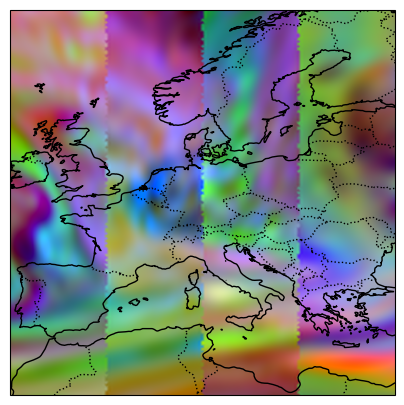

In [36]:
lon_step = (lon_max - lon_min) / 4
viz_bbox1 = lon_min, lat_min, lon_min + lon_step, lat_max
viz_bbox2 = lon_min + lon_step, lat_min, lon_min + 2 * lon_step, lat_max
viz_bbox3 = lon_min + 2 * lon_step, lat_min, lon_min + 3 * lon_step, lat_max
viz_bbox4 = lon_min + 3 * lon_step, lat_min, lon_min + 4 * lon_step, lat_max
viz_bboxes = [viz_bbox1, viz_bbox2, viz_bbox3, viz_bbox4]

VIZ_DATE = '2019-06-15'  # exemplary date for patch-stitching visualization
N_VIZ = 8000

viz_gps_list, viz_Y_list = [], []
for bbox in viz_bboxes:
    Generator.load_data(bbox=bbox, vars=VARS, filename=f'{VIZ_DATE}.nc')
    normed_values, normed_coords, meta = Generator.generate_normed_sample(N=N_VIZ, method='random')
    X = normed_values.numpy()
    print(f'{VIZ_DATE}: running SpatialPCA on strip with {X.shape[0]} points ...', end='\r')
    viz_Y_list.append(spatialpca_embed(X, normed_coords))
    viz_gps_list.append(meta['gps'])

print('Done.                                          ')

locations = pd.DataFrame(np.vstack(viz_gps_list), columns=['lat', 'lon'])
pred_spatialpca_combined = pd.DataFrame(np.vstack(viz_Y_list), columns=['x1', 'x2', 'x3'])
pred_spatialpca_combined = pd.concat([locations, pred_spatialpca_combined], axis=1)

fig = rgb_scale(pred_spatialpca_combined, percentile=0.5, figsize=(5, 5))


## 3. Patch Gluing

Split the full region into two patches overlapping by `2 * margin` degrees of longitude
(`side_crop` trims the top/bottom edges to avoid boundary artifacts), and embed each independently
with SpatialPCA. Points within a 2° border strip of the shared edge in each patch are matched to
their nearest neighbor (in `normed_coords`) in the other patch's border strip — the same
border-matching approach as patch stitching, applied to this overlapping layout.

Each patch's embedding is standardized to unit variance per component before computing distances,
so MSE reflects embedding *consistency* rather than an arbitrary difference in each patch's output
scale. MSE is then `mean(sum((z_A - z_B)**2))` over the matched points, both directions combined.


In [37]:
lat_range = (lat_max - lat_min) / 2
lon_range = (lon_max - lon_min) / 2
MARGIN = 2      # degrees of overlap between the two patches
SIDE_CROP = 7   # degrees trimmed off the top/bottom (and outer) edges
N_GLUE = 10000  # requested points per patch; both patches here have fewer grid cells than
                # this, so generate_normed_sample effectively returns their full grid

gluing_bbox_A = lon_min + SIDE_CROP, lat_min + SIDE_CROP, lon_max - lon_range + MARGIN, lat_max - SIDE_CROP
gluing_bbox_B = lon_min + lon_range - MARGIN, lat_min + SIDE_CROP, lon_max - SIDE_CROP, lat_max - SIDE_CROP


def sample_glued_patch(bbox, date):
    Generator.load_data(bbox=bbox, vars=VARS, filename=f'{date}.nc')
    normed_values, normed_coords, meta = Generator.generate_normed_sample(N=N_GLUE, method='random')
    X = normed_values.numpy()
    gps = pd.DataFrame(meta['gps'], columns=['lat', 'lon'])
    return X, normed_coords, gps


def border_strip_indices(gps_A, gps_B):
    # points in A within edge_margin of its right edge (shared border), and points in B
    # within edge_margin of its left edge
    idx_A = np.where(gps_A['lon'].to_numpy() > (gluing_bbox_A[2] - EDGE_MARGIN))[0]
    idx_B = np.where(gps_B['lon'].to_numpy() < (gluing_bbox_B[0] + EDGE_MARGIN))[0]
    return idx_A, idx_B


def standardize(emb, eps=1e-12):
    return (emb - emb.mean(axis=0)) / (emb.std(axis=0) + eps)


def compute_glue_mse(coords_A, emb_A, idx_A, coords_B, emb_B, idx_B):
    if len(idx_A) < 2 or len(idx_B) < 2:
        return np.nan, 0

    emb_A, emb_B = standardize(emb_A), standardize(emb_B)
    strip_coords_A, strip_emb_A = coords_A[idx_A], torch.from_numpy(emb_A[idx_A])
    strip_coords_B, strip_emb_B = coords_B[idx_B], torch.from_numpy(emb_B[idx_B])

    tree_B = cKDTree(strip_coords_B)
    _, matched_AtoB = tree_B.query(strip_coords_A)
    dist_AtoB = torch.norm(strip_emb_A - strip_emb_B[matched_AtoB], dim=1)

    tree_A = cKDTree(strip_coords_A)
    _, matched_BtoA = tree_A.query(strip_coords_B)
    dist_BtoA = torch.norm(strip_emb_B - strip_emb_A[matched_BtoA], dim=1)

    dist_all = torch.hstack([dist_AtoB, dist_BtoA])
    mse = float((dist_all ** 2).mean())
    return mse, dist_all.shape[0]


In [38]:
gluing_records = []
last_gluing_result = None  # kept for the visualization cell below

for date in DATES:
    X_A, coords_A, gps_A = sample_glued_patch(gluing_bbox_A, date)
    X_B, coords_B, gps_B = sample_glued_patch(gluing_bbox_B, date)
    idx_A, idx_B = border_strip_indices(gps_A, gps_B)

    print(f'{date}: running SpatialPCA on 2 glued patches ({len(idx_A)}/{len(idx_B)} border points) ...', end='\r')
    Y_A = spatialpca_embed(X_A, coords_A)
    Y_B = spatialpca_embed(X_B, coords_B)
    last_gluing_result = (Y_A, Y_B, gps_A, gps_B, idx_A, idx_B)

    mse, n_matched = compute_glue_mse(coords_A, Y_A, idx_A, coords_B, Y_B, idx_B)
    gluing_records.append({'date': date, 'n_matched': n_matched, 'mse': mse})

print('Done.                                          ')
gluing_df = pd.DataFrame(gluing_records)
gluing_df


requested number of points larger then dataset
-> return full dataset of 6405 points.
requested number of points larger then dataset
-> return full dataset of 6405 points.
requested number of points larger then datasethes (840/840 border points) ...
-> return full dataset of 6405 points.
requested number of points larger then dataset
-> return full dataset of 6405 points.
requested number of points larger then datasethes (840/840 border points) ...
-> return full dataset of 6405 points.
requested number of points larger then dataset
-> return full dataset of 6405 points.
requested number of points larger then datasethes (840/840 border points) ...
-> return full dataset of 6405 points.
requested number of points larger then dataset
-> return full dataset of 6405 points.
requested number of points larger then datasethes (840/840 border points) ...
-> return full dataset of 6405 points.
requested number of points larger then dataset
-> return full dataset of 6405 points.
Done.           

,date,n_matched,mse
0,2018-01-01,1680,4.002850
1,2018-01-02,1680,3.033865
2,2018-01-03,1680,4.909028
3,2018-01-04,1680,2.711129
4,2018-01-05,1680,3.542415


In [39]:
# mean +- std across dates
gluing_df[['mse']].agg(mean_std_str).rename('SpatialPCA').to_frame()


,SpatialPCA
mse,3.640 ± 0.863


### Visualization

Stack both patches' locations and their independently-computed SpatialPCA embeddings into one
combined map, and render with `rgb`'s interpolated surface. Because patches A and B overlap, the
overlap band is covered by both patches' independent embeddings — inconsistencies between them
show up as visible discontinuities there.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.13429212007327904..0.9428782196736984].


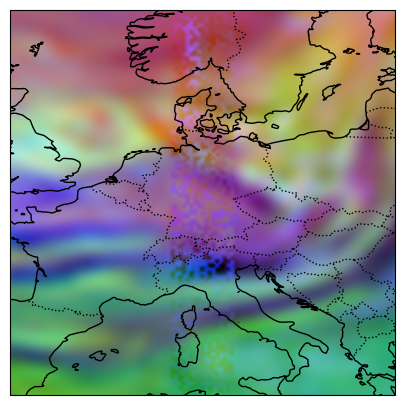

In [40]:
Y_A, Y_B, gps_A, gps_B, idx_A, idx_B = last_gluing_result

locations = pd.DataFrame(np.vstack([gps_A.to_numpy(), gps_B.to_numpy()]), columns=['lat', 'lon'])
pred_spatialpca_combined = pd.DataFrame(np.vstack([Y_A, Y_B]), columns=['x1', 'x2', 'x3'])
pred_spatialpca_combined = pd.concat([locations, pred_spatialpca_combined], axis=1)

fig = rgb(pred_spatialpca_combined, figsize=(5, 5))
